# LIDC-IDRI: Chapter 3 experiment

Reproducible comparison of low/high radiologist-rated suspicion. This notebook reads
recorded experimental outputs. Preprocessing success is not predictive-performance evidence.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
if not (ROOT / "configs").exists():
    ROOT = ROOT.parent
ARTIFACTS = ROOT / "artifacts/chapter3"
print("Artifact directory:", ARTIFACTS)
status = ARTIFACTS / "status.json"
print(json.loads(status.read_text()) if status.exists() else "No CLI stage completion recorded yet.")

Artifact directory: C:\Workspace\research-project\artifacts\chapter3
{'last_completed_stage': 'report', 'profile': 'primary'}


## Run the staged experiment

From the repository root: `python -m lidc_experiment run --config configs/chapter3.yaml`.
Replace `run` with a stage to resume: `prepare`, `features`, `split`, `tune`, `fit`,
`thresholds`, `secondary`, `explain`, `check`, `freeze`, `evaluate`, `benchmark`, `report`.
Inspect development overlays before freezing. Limits and reduced grids require a separate smoke profile.

In [2]:
def table(relative):
    path = ARTIFACTS / relative
    if path.exists():
        result = pd.read_csv(path)
        display(result)
        return result
    print("Not produced yet:", relative)

summary = ARTIFACTS / "cohort_summary.json"
if summary.exists():
    display(json.loads(summary.read_text()))
else:
    print("Final common cohort is not frozen yet.")
table("training/cv_results.csv")

{'prepared_nodules': 1594,
 'feature_success_nodules': 1594,
 'feature_excluded': 0,
 'mean_indeterminate': 1049,
 'binary_nodules': 545,
 'binary_patients': 368,
 'partitions': {'test': {'patients': 56, 'nodules': 90, 'low': 58, 'high': 32},
  'train': {'patients': 257, 'nodules': 379, 'low': 229, 'high': 150},
  'validation': {'patients': 55, 'nodules': 76, 'low': 42, 'high': 34}},
 'manifest_sha256': '622432ef685b82ebed4589539378f09dd04c5262b1ffeef05983e3c938e5e417',
 'endpoint': 'low versus high radiologist-rated nodule malignancy suspicion'}

,model,candidate,fold,settings,fingerprint,status,auc,best_epoch,warnings,wall_seconds
0,logistic_regression,0,0,"{""C"": 0.001, ""class_weight"": null}",58c90cc58aee971714781a50dc68623971987d11a2a861...,success,0.992857,NaN,[],0.090576
1,logistic_regression,0,1,"{""C"": 0.001, ""class_weight"": null}",fd1cdb65bd0873250f78d2a08aa0fdd15d8efd8f4bc448...,success,0.988419,NaN,[],0.087224
2,logistic_regression,0,2,"{""C"": 0.001, ""class_weight"": null}",ac38620ace526c7bf5650659155b94779b6b1a3328ba3d...,success,0.983056,NaN,[],0.086461
3,logistic_regression,1,0,"{""C"": 0.001, ""class_weight"": ""balanced""}",5f39026fb7e632f5d8a2f256161859f8f328fe4018e097...,success,0.993103,NaN,[],0.087764
4,logistic_regression,1,1,"{""C"": 0.001, ""class_weight"": ""balanced""}",813b16668d219c35d8edb636f30186bd597cb7ecd66dfe...,success,0.988419,NaN,[],0.084621
...,...,...,...,...,...,...,...,...,...,...
139,cnn,10,1,"{""dropout"": 0.5, ""learning_rate"": 0.001, ""weig...",fe89c2fb311e2f29943a7e19c34da97a7888e034e282aa...,success,0.964988,1.0,[],1.113090
140,cnn,10,2,"{""dropout"": 0.5, ""learning_rate"": 0.001, ""weig...",07789854fa52ba879fb17082e55c5d821d0398f812c231...,success,0.969444,1.0,[],1.326251
141,cnn,11,0,"{""dropout"": 0.5, ""learning_rate"": 0.001, ""weig...",b0457a53acbe3331a0d67708a095371e3478936ded158a...,success,0.955665,1.0,[],1.361896
142,cnn,11,1,"{""dropout"": 0.5, ""learning_rate"": 0.001, ""weig...",8e458bddcdeb3f818a8733c71a61ddae32bdbf117a7162...,success,0.969028,8.0,[],2.125497


,model,candidate,fold,settings,fingerprint,status,auc,best_epoch,warnings,wall_seconds
0,logistic_regression,0,0,"{""C"": 0.001, ""class_weight"": null}",58c90cc58aee971714781a50dc68623971987d11a2a861...,success,0.992857,NaN,[],0.090576
1,logistic_regression,0,1,"{""C"": 0.001, ""class_weight"": null}",fd1cdb65bd0873250f78d2a08aa0fdd15d8efd8f4bc448...,success,0.988419,NaN,[],0.087224
2,logistic_regression,0,2,"{""C"": 0.001, ""class_weight"": null}",ac38620ace526c7bf5650659155b94779b6b1a3328ba3d...,success,0.983056,NaN,[],0.086461
3,logistic_regression,1,0,"{""C"": 0.001, ""class_weight"": ""balanced""}",5f39026fb7e632f5d8a2f256161859f8f328fe4018e097...,success,0.993103,NaN,[],0.087764
4,logistic_regression,1,1,"{""C"": 0.001, ""class_weight"": ""balanced""}",813b16668d219c35d8edb636f30186bd597cb7ecd66dfe...,success,0.988419,NaN,[],0.084621
...,...,...,...,...,...,...,...,...,...,...
139,cnn,10,1,"{""dropout"": 0.5, ""learning_rate"": 0.001, ""weig...",fe89c2fb311e2f29943a7e19c34da97a7888e034e282aa...,success,0.964988,1.0,[],1.113090
140,cnn,10,2,"{""dropout"": 0.5, ""learning_rate"": 0.001, ""weig...",07789854fa52ba879fb17082e55c5d821d0398f812c231...,success,0.969444,1.0,[],1.326251
141,cnn,11,0,"{""dropout"": 0.5, ""learning_rate"": 0.001, ""weig...",b0457a53acbe3331a0d67708a095371e3478936ded158a...,success,0.955665,1.0,[],1.361896
142,cnn,11,1,"{""dropout"": 0.5, ""learning_rate"": 0.001, ""weig...",8e458bddcdeb3f818a8733c71a61ddae32bdbf117a7162...,success,0.969028,8.0,[],2.125497


In [3]:
table("results/metrics.csv")
table("results/metric_intervals.csv")
comparison = ARTIFACTS / "results/primary_comparison.json"
if comparison.exists():
    display(json.loads(comparison.read_text()))

,n_nodules,positive_nodules,prevalence,threshold,tp,fn,tn,fp,roc_auc,average_precision,...,balanced_accuracy,sensitivity,specificity,precision,f1,brier_score,model,n_patients,weighting,threshold_basis
0,90,32,0.355556,0.514562,24.0,8.0,57.0,1.0,0.940194,0.932199,...,0.866379,0.75000,0.982759,0.960000,0.842105,0.252447,cnn,56,nodule,native_score
1,90,32,0.355556,0.691634,23.0,9.0,57.0,1.0,0.965517,0.960609,...,0.850754,0.71875,0.982759,0.958333,0.821429,0.057953,logistic_regression,56,nodule,native_score
2,90,32,0.355556,0.642000,27.0,5.0,57.0,1.0,0.965787,0.963117,...,0.913254,0.84375,0.982759,0.964286,0.900000,0.055249,random_forest,56,nodule,native_score
3,90,32,0.355556,0.256217,28.0,4.0,56.0,2.0,0.957974,0.952979,...,0.920259,0.87500,0.965517,0.933333,0.903226,0.052811,svm,56,nodule,native_score


,model,metric,estimate,lower_95,upper_95,valid_metric_replicates
0,cnn,roc_auc,0.940194,0.860955,0.993211,2000
1,cnn,average_precision,0.932199,0.841350,0.988636,2000
2,cnn,accuracy,0.900000,0.824728,0.958773,2000
3,cnn,balanced_accuracy,0.866379,0.772458,0.943151,2000
4,cnn,sensitivity,0.750000,0.566603,0.904870,2000
5,cnn,specificity,0.982759,0.943396,1.000000,2000
6,cnn,precision,0.960000,0.863636,1.000000,2000
7,cnn,f1,0.842105,0.705828,0.937500,2000
8,cnn,brier_score,0.252447,0.248822,0.255740,2000
9,logistic_regression,roc_auc,0.965517,0.912004,0.998439,2000


{'comparison': 'cnn minus random_forest',
 'primary_metric': 'roc_auc',
 'positive_class': 'high radiologist-rated suspicion',
 'unit': 'nodule',
 'resampling_unit': 'patient',
 'interval': '95% percentile patient-cluster bootstrap',
 'seed': 42,
 'requested_replicates': 2000,
 'valid_replicates': 2000,
 'attempts': 2000,
 'rejected_single_class': 0,
 'reliable': True,
 'interpretation': 'favors_selected_traditional_model',
 'differences': {'roc_auc': {'estimate': -0.02559267241379304,
   'lower_95': -0.05909453626867785,
   'upper_95': -0.0024786246348216176,
   'valid_metric_replicates': 2000},
  'sensitivity': {'estimate': -0.09375,
   'lower_95': -0.2413793103448275,
   'upper_95': 0.03228494623655907,
   'valid_metric_replicates': 2000},
  'specificity': {'estimate': 0.0,
   'lower_95': -0.050000000000000044,
   'upper_95': 0.054545454545454564,
   'valid_metric_replicates': 2000}},
 'uncertainty_scope': 'Test-patient sampling conditional on fixed models and thresholds; excludes t

In [4]:
table("secondary/development_metrics.csv")
table("secondary/mask_sensitivity.csv")
table("resources/latency_summary.csv")
table("resources/training_resources.csv")
table("resources/component_summary.csv")

,analysis,detail,model,seed,training_patients,training_nodules,validation_patients,validation_nodules,roc_auc,average_precision,fit_wall_seconds,settings
0,learning_curve,fraction_0.25,logistic_regression,42,65,113,55,76,0.992997,0.992979,0.045486,"{""C"": 0.01, ""class_weight"": null}"
1,learning_curve,fraction_0.25,svm,42,65,113,55,76,0.986695,0.987372,0.041042,"{""C"": 1.0, ""class_weight"": null, ""gamma"": 0.01}"
2,learning_curve,fraction_0.25,random_forest,42,65,113,55,76,0.981793,0.984165,0.454345,"{""class_weight"": ""balanced"", ""max_depth"": null..."
3,learning_curve,fraction_0.25,cnn,42,65,113,55,76,0.974090,0.978369,2.421598,"{""dropout"": 0.2, ""learning_rate"": 0.001, ""weig..."
4,learning_curve,fraction_0.50,logistic_regression,42,129,208,55,76,0.991597,0.991945,0.048746,"{""C"": 0.01, ""class_weight"": null}"
5,learning_curve,fraction_0.50,svm,42,129,208,55,76,0.988796,0.989189,0.046078,"{""C"": 1.0, ""class_weight"": null, ""gamma"": 0.01}"
6,learning_curve,fraction_0.50,random_forest,42,129,208,55,76,0.985294,0.985984,0.639084,"{""class_weight"": ""balanced"", ""max_depth"": null..."
7,learning_curve,fraction_0.50,cnn,42,129,208,55,76,0.977591,0.979938,0.173372,"{""dropout"": 0.2, ""learning_rate"": 0.001, ""weig..."
8,learning_curve,fraction_0.75,logistic_regression,42,193,295,55,76,0.990896,0.991462,0.048506,"{""C"": 0.01, ""class_weight"": null}"
9,learning_curve,fraction_0.75,svm,42,193,295,55,76,0.990196,0.991000,0.044687,"{""C"": 1.0, ""class_weight"": null, ""gamma"": 0.01}"


,nodule_id,variant,reader_index,model,status,original_slice,alternative_slice,original_score,alternative_score,score_change
0,n_02c21fc4dfe539e988d9,strict,NaN,logistic_regression,success,240,237,0.873664,0.831616,-0.042048
1,n_02c21fc4dfe539e988d9,strict,NaN,svm,success,240,237,1.939469,1.724612,-0.214857
2,n_02c21fc4dfe539e988d9,strict,NaN,random_forest,success,240,237,1.000000,0.998000,-0.002000
3,n_02c21fc4dfe539e988d9,strict,NaN,cnn,success,240,237,0.517894,0.517624,-0.000270
4,n_02c21fc4dfe539e988d9,individual,0.0,logistic_regression,success,240,239,0.873664,0.872391,-0.001272
...,...,...,...,...,...,...,...,...,...,...
459,n_ff5dca6e4eb22d30656f,individual,1.0,cnn,success,261,261,0.517817,0.517708,-0.000109
460,n_ff5dca6e4eb22d30656f,individual,2.0,logistic_regression,success,261,262,0.919342,0.931906,0.012564
461,n_ff5dca6e4eb22d30656f,individual,2.0,svm,success,261,262,1.725562,1.733587,0.008024
462,n_ff5dca6e4eb22d30656f,individual,2.0,random_forest,success,261,262,0.988000,0.992000,0.004000


,model,definition,median,q25,q75,samples,iqr
0,cnn,decoded_ct_pipeline_uncached_features,0.019968,0.013596,0.036621,450,0.023026
1,cnn,model_only,0.001197,0.001159,0.001245,450,0.000087
2,logistic_regression,decoded_ct_pipeline_uncached_features,0.041108,0.032548,0.059121,450,0.026573
3,logistic_regression,model_only,0.000202,0.000197,0.000213,450,0.000016
4,random_forest,decoded_ct_pipeline_uncached_features,0.067330,0.054543,0.085762,450,0.031219
5,random_forest,model_only,0.018055,0.017753,0.018500,450,0.000747
6,svm,decoded_ct_pipeline_uncached_features,0.040941,0.032381,0.059078,450,0.026697
7,svm,model_only,0.000234,0.000226,0.000242,450,0.000016


,model,search_wall_seconds,cv_fit_and_scoring_seconds,final_fit_wall_seconds,fit_device,inference_device,cpu_threads,saved_model_bytes,fitted_feature_dimension,peak_process_rss_bytes,peak_cuda_allocated_bytes
0,logistic_regression,4.207290,3.545660,0.052850,cpu,cpu,1,12355,41.0,628219904,0
1,svm,4.390421,3.578870,0.228307,cpu,cpu,1,48671,41.0,630538240,0
2,random_forest,27.716024,27.024491,0.708620,cpu,cpu,1,376016,41.0,629862400,0
3,cnn,51.544080,48.750878,2.546146,cuda,cpu,1,125109,NaN,1335775232,98966528


,component,median,q25,q75,iqr,samples,unit
0,common_preparation_seconds,0.022209,0.014384,0.038393,0.024009,90,seconds
1,radiomics_extraction_seconds,0.016367,0.014905,0.018672,0.003767,90,seconds
2,radiomics_dataframe_seconds,0.000940,0.000915,0.001165,0.000250,90,seconds
3,cnn_tensor_preparation_seconds,0.000054,0.000053,0.000059,0.000006,90,seconds
4,logistic_regression_transform_prediction_seconds,0.007833,0.007493,0.008543,0.001050,90,seconds
5,logistic_regression_route_sum_seconds,0.048896,0.039366,0.070960,0.031594,90,seconds
6,svm_transform_prediction_seconds,0.007722,0.007163,0.008826,0.001664,90,seconds
7,svm_route_sum_seconds,0.048841,0.039713,0.070997,0.031284,90,seconds
8,random_forest_transform_prediction_seconds,0.034704,0.033604,0.037318,0.003714,90,seconds
9,random_forest_route_sum_seconds,0.078067,0.066927,0.098188,0.031261,90,seconds


,component,median,q25,q75,iqr,samples,unit
0,common_preparation_seconds,0.022209,0.014384,0.038393,0.024009,90,seconds
1,radiomics_extraction_seconds,0.016367,0.014905,0.018672,0.003767,90,seconds
2,radiomics_dataframe_seconds,0.000940,0.000915,0.001165,0.000250,90,seconds
3,cnn_tensor_preparation_seconds,0.000054,0.000053,0.000059,0.000006,90,seconds
4,logistic_regression_transform_prediction_seconds,0.007833,0.007493,0.008543,0.001050,90,seconds
5,logistic_regression_route_sum_seconds,0.048896,0.039366,0.070960,0.031594,90,seconds
6,svm_transform_prediction_seconds,0.007722,0.007163,0.008826,0.001664,90,seconds
7,svm_route_sum_seconds,0.048841,0.039713,0.070997,0.031284,90,seconds
8,random_forest_transform_prediction_seconds,0.034704,0.033604,0.037318,0.003714,90,seconds
9,random_forest_route_sum_seconds,0.078067,0.066927,0.098188,0.031261,90,seconds


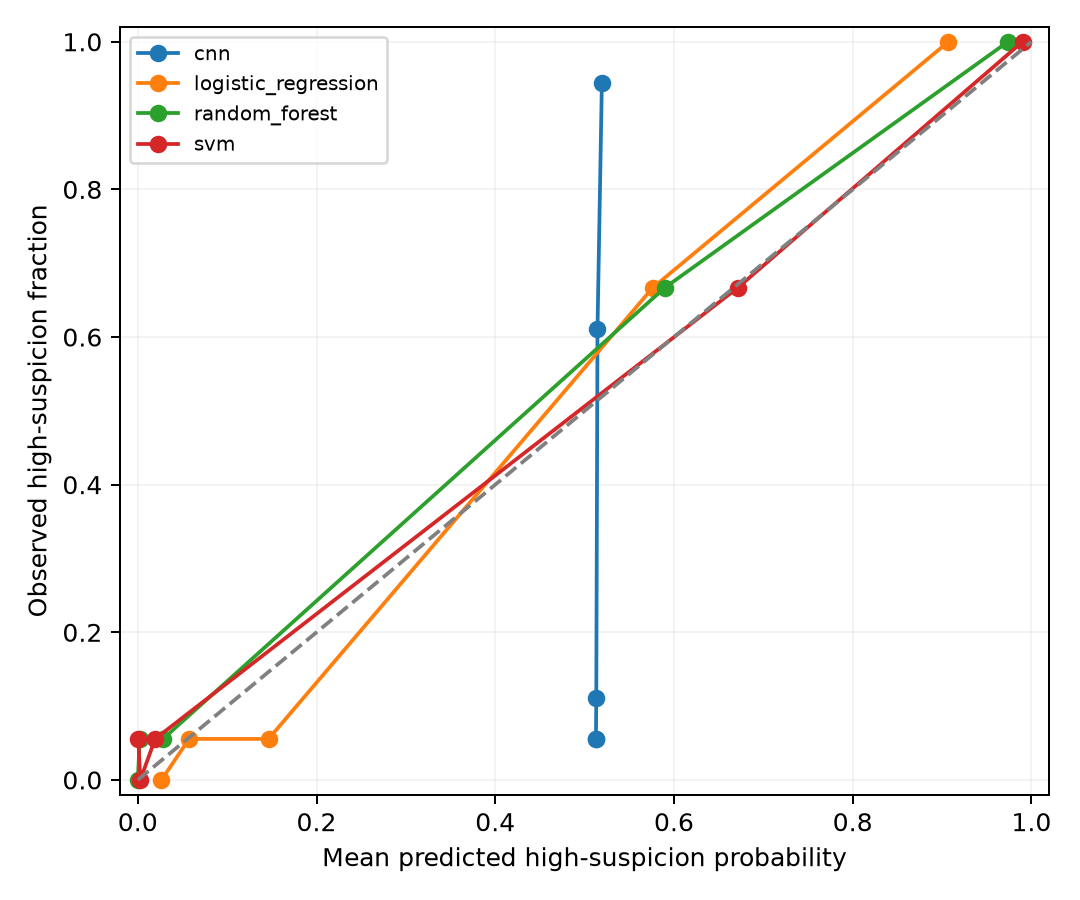

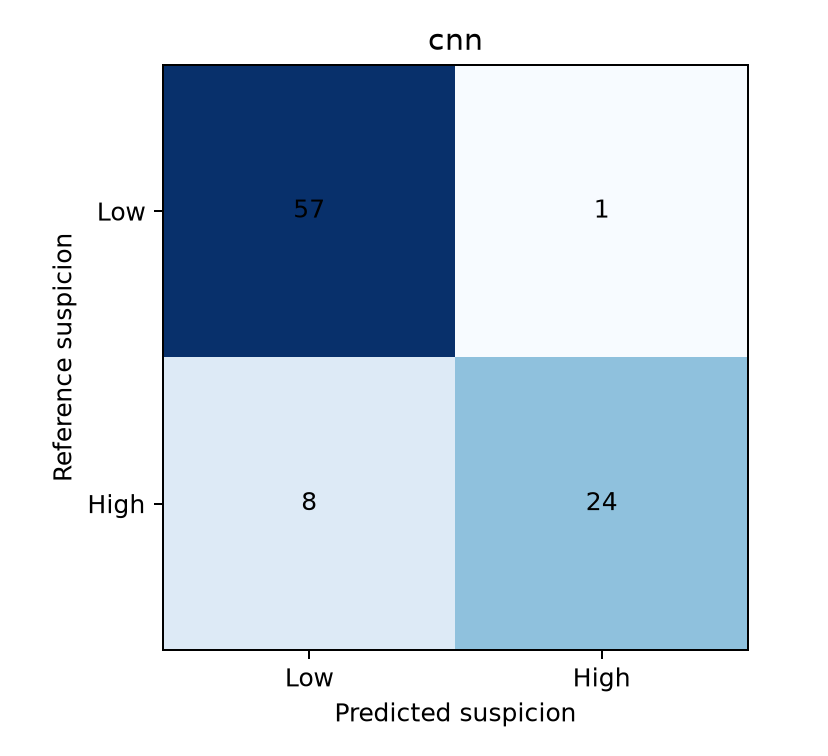

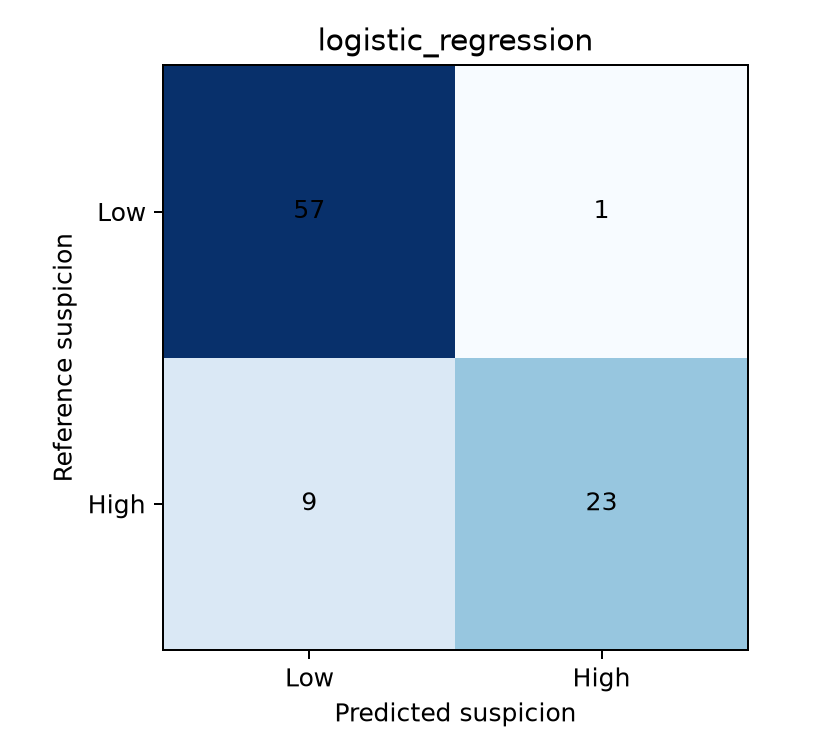

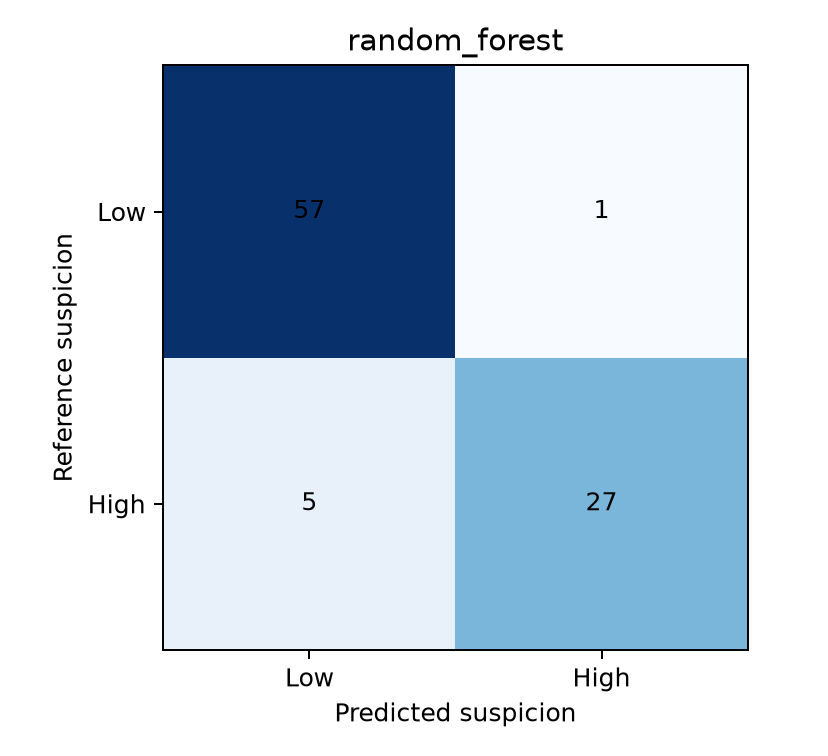

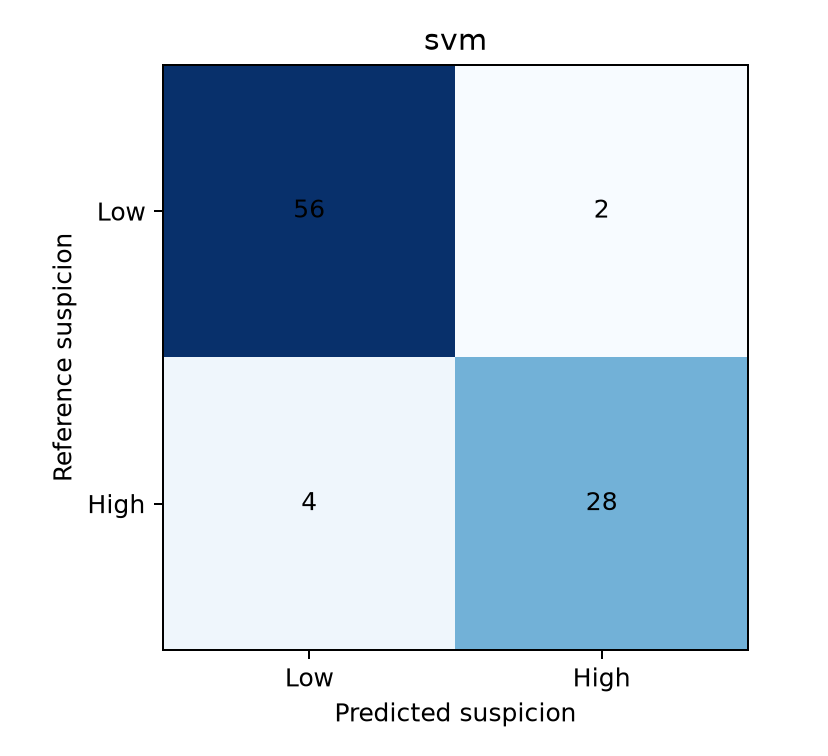

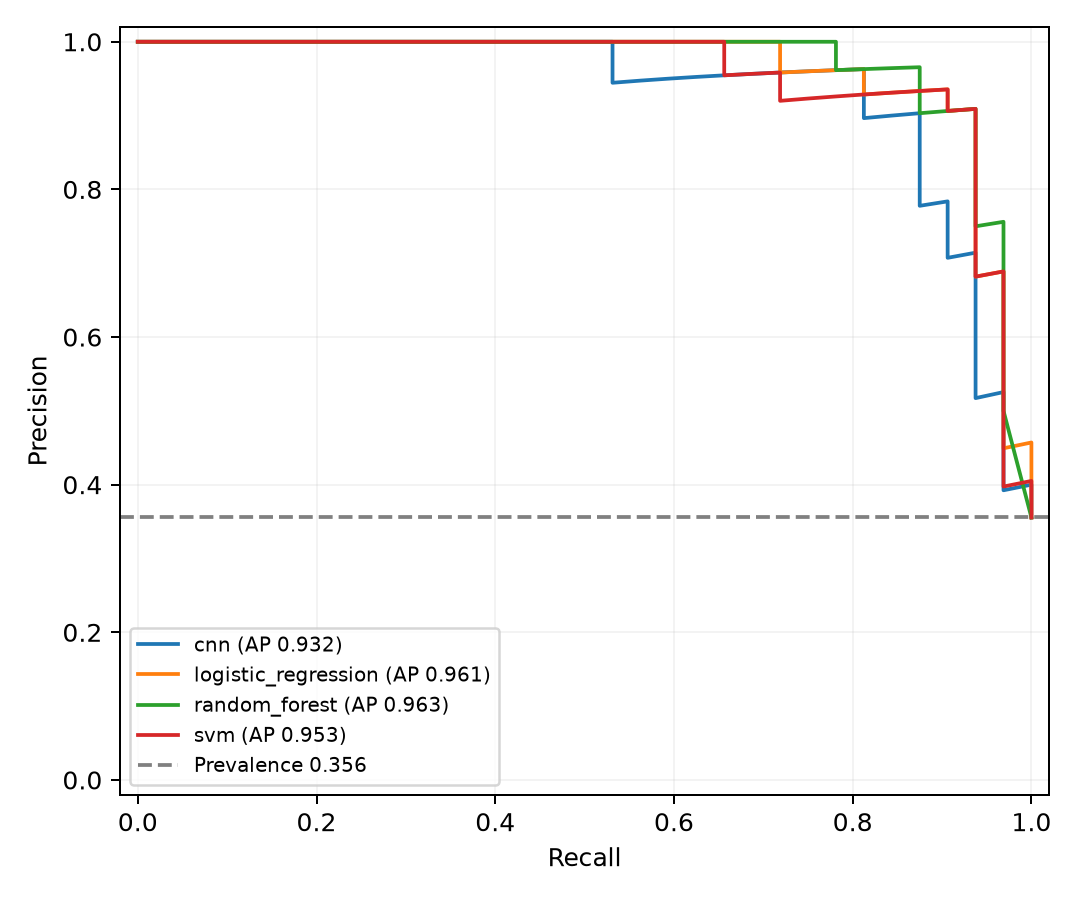

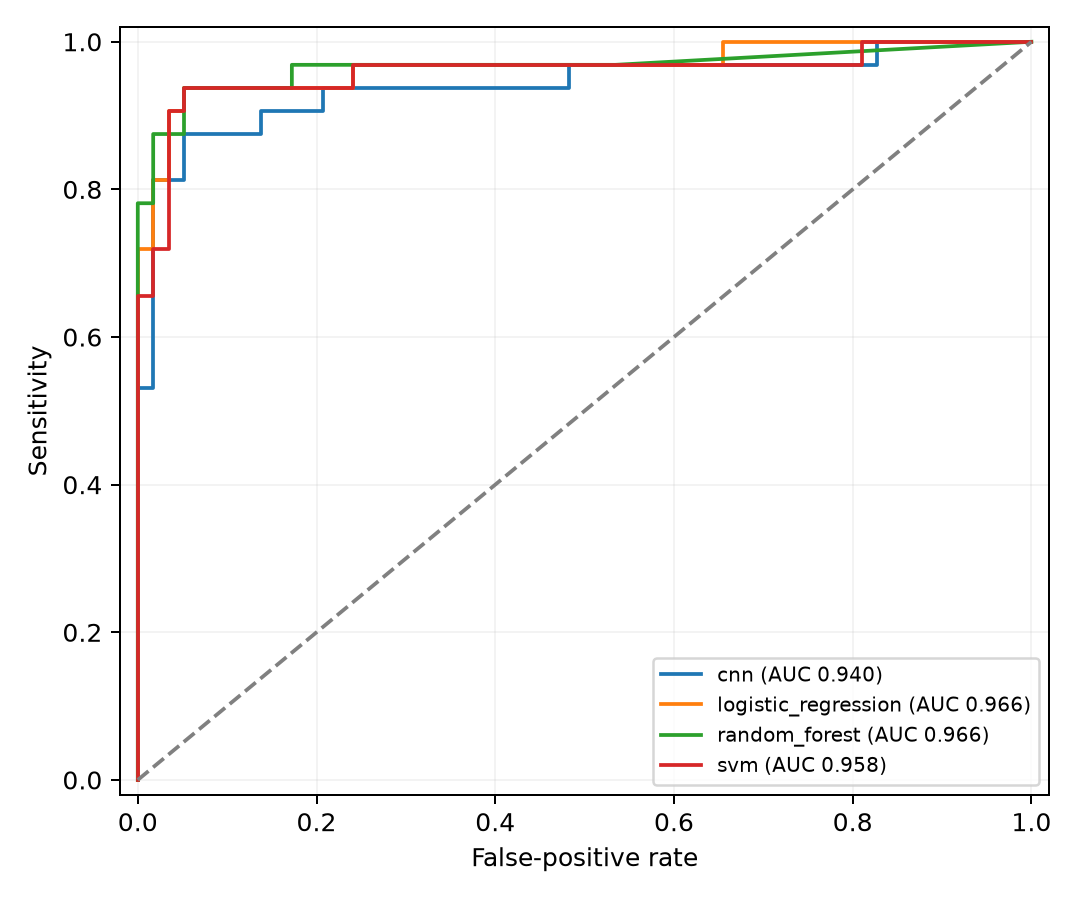

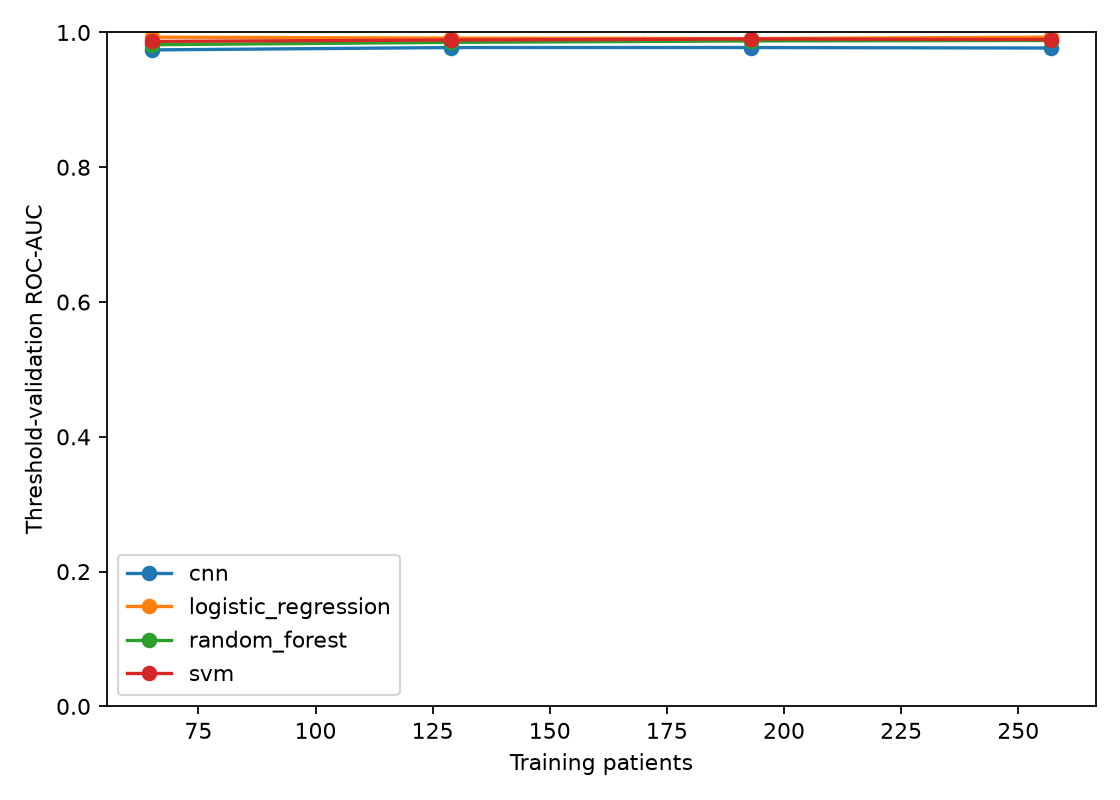

In [5]:
for path in sorted((ARTIFACTS / "results/figures").glob("*.png")):
    display(Image(filename=str(path)))
learning = ARTIFACTS / "secondary/learning_curves.png"
if learning.exists():
    display(Image(filename=str(learning)))

## Prepared-case viewer and interpretation

Use `python -m lidc_experiment view --nodule-id ID` with an identifier from `cohort.csv`.
It generates a local HTML view containing the supplied contour, model scores and thresholds.
Full CT examinations are unsupported; test-case predictions require completed final evaluation.

Reference labels represent radiologist suspicion, not pathology-confirmed cancer.
A confidence interval spanning zero is inconclusive and does not establish equivalence.
Read the [interpretation notes](../artifacts/chapter3/CHAPTER4_INTERPRETATION.md)
for the primary comparison, calibration limitations, explanation checks and exact timing boundaries.